Loading credit_card_balance sample...
Loaded 200,000 monthly statements for 70,494 credit card holders.
Matched with 9,349 cardholders in application_train.csv.


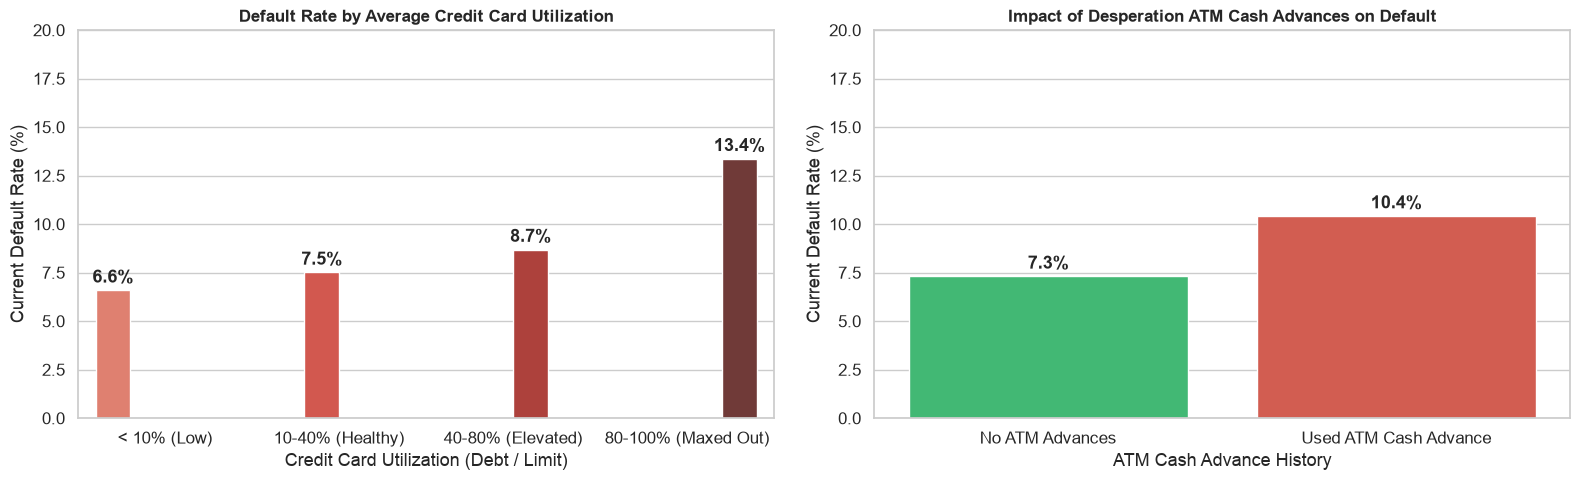

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid", font_scale=1.1)

# Smart Path Finder
data_dir = Path("data") if Path("data").exists() else (Path("../data") if Path("../data").exists() else Path("../../data"))

print("Loading credit_card_balance sample...")
# Load a 200k row sample for instantaneous, responsive plotting
use_cols = ['SK_ID_CURR', 'AMT_BALANCE', 'AMT_CREDIT_LIMIT_ACTUAL', 'AMT_DRAWINGS_ATM_CURRENT']
cc = pd.read_csv(data_dir / "credit_card_balance.csv", usecols=use_cols, nrows=200000)
app = pd.read_csv(data_dir / "application_train.csv", usecols=["SK_ID_CURR", "TARGET"], nrows=50000)

print(f"Loaded {len(cc):,} monthly statements for {cc['SK_ID_CURR'].nunique():,} credit card holders.")


# 1. Feature Engineering: Utilization Ratio
# Clip at 1.0 (100% maxed out) to handle zero/low limit edge cases cleanly
cc["UTILIZATION"] = (cc["AMT_BALANCE"] / (cc["AMT_CREDIT_LIMIT_ACTUAL"] + 1e-5)).clip(0, 1.0)


# 2. Aggregate per Applicant (1 row per cardholder)
cc_agg = cc.groupby("SK_ID_CURR").agg(
    CC_BALANCE_MAX=("AMT_BALANCE", "max"),
    CC_UTILIZATION_MEAN=("UTILIZATION", "mean"),
    CC_TOTAL_ATM_DRAWINGS=("AMT_DRAWINGS_ATM_CURRENT", "sum")
).reset_index()

# Merge with Target
merged_cc = app.merge(cc_agg, on="SK_ID_CURR", how="inner")
print(f"Matched with {len(merged_cc):,} cardholders in application_train.csv.")


# 3. Side-by-Side Visualizations
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# ─── Panel 1: Card Utilization vs Default Rate ───
merged_cc["UTIL_BIN"] = pd.cut(
    merged_cc["CC_UTILIZATION_MEAN"],
    bins=[-0.1, 0.10, 0.40, 0.80, 1.0],
    labels=["< 10% (Low)", "10-40% (Healthy)", "40-80% (Elevated)", "80-100% (Maxed Out)"]
)
default_by_util = merged_cc.groupby("UTIL_BIN", observed=False)["TARGET"].mean() * 100

sns.barplot(
    x=default_by_util.index,
    y=default_by_util.values,
    hue=default_by_util.index,
    palette="Reds_d",
    legend=False,
    ax=ax1
)
ax1.set_title("Default Rate by Average Credit Card Utilization", fontsize=12, fontweight="bold")
ax1.set_xlabel("Credit Card Utilization (Debt / Limit)")
ax1.set_ylabel("Current Default Rate (%)")
ax1.set_ylim(0, 20)
for p in ax1.patches:
    ax1.annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2, p.get_height() + 0.4), ha="center", fontweight="bold")


# ─── Panel 2: Took ATM Cash Advance vs Default Rate ───
merged_cc["USED_ATM_CASH"] = (merged_cc["CC_TOTAL_ATM_DRAWINGS"] > 0).astype(int)
default_by_atm = merged_cc.groupby("USED_ATM_CASH")["TARGET"].mean() * 100
atm_labels = ["No ATM Advances", "Used ATM Cash Advance"]

sns.barplot(
    x=atm_labels,
    y=default_by_atm.values,
    hue=atm_labels,
    palette=["#2ecc71", "#e74c3c"],
    legend=False,
    ax=ax2
)
ax2.set_title("Impact of Desperation ATM Cash Advances on Default", fontsize=12, fontweight="bold")
ax2.set_xlabel("ATM Cash Advance History")
ax2.set_ylabel("Current Default Rate (%)")
ax2.set_ylim(0, 20)
for p in ax2.patches:
    ax2.annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2, p.get_height() + 0.4), ha="center", fontweight="bold")

plt.tight_layout()
plt.show()